# 07. Ajuste de modelos

Entrena los cuatro algoritmos de la revisión bibliográfica (regresión logística, Random Forest, Gradient Boosting y perceptrón multicapa), compara la configuración por defecto con la ajustada por búsqueda aleatoria y calcula la importancia por permutación de cada variable.

- Entrenamiento: ofertas del 1 de marzo al 16 de abril de 2013.
- Validación: del 17 al 23 de abril. Aquí se eligen los hiperparámetros.
- Prueba: del 24 al 30 de abril. **Este notebook no la toca**; la evalúa el notebook 08.

Los modelos finales se guardan congelados en `results/modelos/` con su ficha en `manifiesto.json`.

In [1]:
from pathlib import Path
import os
import sys
import time
import warnings

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'src').exists():
    ROOT_DIR = ROOT_DIR.parent
sys.path.insert(0, str(ROOT_DIR / 'src'))

from config import FIGURES_DIR, MODELS_DIR, TABLES_DIR
from modelo import (
    ALGORITMOS,
    FIN_ENTRENAMIENTO,
    FIN_VALIDACION,
    ajustar_y_evaluar,
    buscar_hiperparametros,
    columnas_entrada_modelo,
    dividir_en_tres_conjuntos,
    importancia_por_permutacion,
    umbral_maximo_f1,
)
from modelos_congelados import cargar_modelos, guardar_modelo_congelado
from preprocesamiento import cargar_dataset_modelo

warnings.filterwarnings('ignore', category=UserWarning)
for carpeta in (FIGURES_DIR, MODELS_DIR, TABLES_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

## División temporal en tres conjuntos

In [2]:
dataset = cargar_dataset_modelo()
division = dividir_en_tres_conjuntos(dataset)
train, validacion, prueba = division.entrenamiento, division.validacion, division.prueba

resumen_division = pd.DataFrame([
    {
        'conjunto': nombre,
        'primera_oferta': conjunto['offerdate'].min().date(),
        'ultima_oferta': conjunto['offerdate'].max().date(),
        'clientes': len(conjunto),
        'recompradores': int(conjunto['repeater'].sum()),
        'tasa_recompra': conjunto['repeater'].mean(),
    }
    for nombre, conjunto in [('entrenamiento', train), ('validacion', validacion), ('prueba', prueba)]
])
resumen_division.to_csv(TABLES_DIR / '07_division_conjuntos.csv', index=False)
resumen_division

,conjunto,primera_oferta,ultima_oferta,clientes,recompradores,tasa_recompra
0,entrenamiento,2013-03-01,2013-04-16,106062,24476,0.230771
1,validacion,2013-04-17,2013-04-23,18496,6214,0.335965
2,prueba,2013-04-24,2013-04-30,35499,12748,0.359109


## Ajuste por algoritmo

Para cada algoritmo se entrena la configuración por defecto de scikit-learn con la misma preparación de variables, se hace una búsqueda aleatoria que ajusta con el entrenamiento y puntúa con la semana de validación, y se vuelve a entrenar con la mejor combinación. Todo se mide con el AUC de la semana de validación.

In [3]:
N_ITER = {
    'regresion_logistica': 30,
    'random_forest': 20,
    'gradient_boosting': 40,
    'perceptron_multicapa': 20,
}
resultados = {}


def ajustar_algoritmo(algoritmo):
    inicio = time.perf_counter()
    por_defecto = ajustar_y_evaluar(algoritmo, train, validacion)
    tabla_busqueda, mejores = buscar_hiperparametros(algoritmo, train, validacion, N_ITER[algoritmo])
    ajustado = ajustar_y_evaluar(algoritmo, train, validacion, **mejores)
    resultados[algoritmo] = {
        'por_defecto': por_defecto,
        'ajustado': ajustado,
        'busqueda': tabla_busqueda,
        'mejores': mejores,
    }
    print(
        f"{algoritmo}: AUC por defecto {por_defecto['auc']:.4f}, "
        f"ajustado {ajustado['auc']:.4f}, {time.perf_counter() - inicio:.0f} s"
    )
    print('Hiperparametros elegidos:', mejores)

In [4]:
ajustar_algoritmo('regresion_logistica')

Fitting 1 folds for each of 30 candidates, totalling 30 fits


regresion_logistica: AUC por defecto 0.6599, ajustado 0.6616, 479 s
Hiperparametros elegidos: {'C': 0.5456725485601477, 'class_weight': 'balanced', 'penalty': 'l2'}


In [5]:
ajustar_algoritmo('random_forest')

Fitting 1 folds for each of 20 candidates, totalling 20 fits


random_forest: AUC por defecto 0.6512, ajustado 0.6804, 986 s
Hiperparametros elegidos: {'class_weight': None, 'max_depth': 24, 'max_features': 0.2, 'min_samples_leaf': 44, 'n_estimators': 563}


In [6]:
ajustar_algoritmo('gradient_boosting')

  File "C:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Fitting 1 folds for each of 40 candidates, totalling 40 fits


gradient_boosting: AUC por defecto 0.6719, ajustado 0.6798, 76 s
Hiperparametros elegidos: {'class_weight': 'balanced', 'early_stopping': True, 'l2_regularization': 0.0340178999112854, 'learning_rate': 0.18738813594563017, 'max_iter': 500, 'max_leaf_nodes': 17, 'min_samples_leaf': 20, 'n_iter_no_change': 20}


In [7]:
ajustar_algoritmo('perceptron_multicapa')

Fitting 1 folds for each of 20 candidates, totalling 20 fits


perceptron_multicapa: AUC por defecto 0.6375, ajustado 0.6843, 373 s
Hiperparametros elegidos: {'alpha': 0.0022673986523780395, 'early_stopping': True, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.0005820013372709853, 'max_iter': 200, 'n_iter_no_change': 10}


## Tamaño de los modelos

GitHub rechaza archivos de más de 100 MB. Si el mejor Random Forest comprimido se pasa de 90 MB, se usa la siguiente mejor combinación de la búsqueda que sí cabe.

In [8]:
LIMITE_MB = 90


def tamano_comprimido_mb(pipeline):
    ruta = TABLES_DIR / '_tamano_temporal.joblib'
    joblib.dump(pipeline, ruta, compress=3)
    tamano = ruta.stat().st_size / 1e6
    ruta.unlink()
    return tamano


tamanos = pd.DataFrame([
    {'algoritmo': a, 'tamano_mb': tamano_comprimido_mb(r['ajustado']['pipeline'])}
    for a, r in resultados.items()
])
tamanos

,algoritmo,tamano_mb
0,regresion_logistica,0.007240
1,random_forest,34.742263
2,gradient_boosting,0.066320
3,perceptron_multicapa,0.351375


In [9]:
if (tamanos['tamano_mb'] > LIMITE_MB).any():
    raise RuntimeError(
        'Un modelo supera el limite de tamano; elige otra combinacion de la tabla de busqueda '
        'o aumenta min_samples_leaf antes de congelar.'
    )
print('Todos los modelos caben bajo', LIMITE_MB, 'MB')

Todos los modelos caben bajo 90 MB


## Congelar los modelos

Cada modelo se guarda una sola vez, con el pipeline completo, y se registra en `manifiesto.json`. Si el archivo ya existe no se sobrescribe: para reentrenar se guarda una versión nueva con otro nombre. El umbral de cada ficha maximiza el F1 en la semana de validación.

In [10]:
PERIODO_ENTRENAMIENTO = f'{train["offerdate"].min().date()} a {FIN_ENTRENAMIENTO}'
PERIODO_VALIDACION = f'{validacion["offerdate"].min().date()} a {FIN_VALIDACION}'
COLUMNAS_ENTRADA = columnas_entrada_modelo(dataset)
y_validacion = validacion['repeater'].astype(int)

for algoritmo in ALGORITMOS:
    nombre = f'07_{algoritmo}'
    ruta = MODELS_DIR / f'{nombre}.joblib'
    if ruta.exists():
        print(f'{nombre} ya esta congelado, no se sobrescribe')
        continue
    ajustado = resultados[algoritmo]['ajustado']
    guardar_modelo_congelado(
        ajustado['pipeline'],
        nombre,
        algoritmo=algoritmo,
        columnas_entrada=COLUMNAS_ENTRADA,
        hiperparametros=resultados[algoritmo]['mejores'],
        auc_validacion=ajustado['auc'],
        umbral=umbral_maximo_f1(y_validacion, ajustado['probabilidades']),
        periodo_entrenamiento=PERIODO_ENTRENAMIENTO,
        periodo_validacion=PERIODO_VALIDACION,
        tiempo_entrenamiento_s=ajustado['tiempo_entrenamiento_s'],
    )
    print(f'{nombre} congelado')

07_regresion_logistica ya esta congelado, no se sobrescribe
07_random_forest ya esta congelado, no se sobrescribe
07_gradient_boosting ya esta congelado, no se sobrescribe
07_perceptron_multicapa ya esta congelado, no se sobrescribe


## Versión 2: reentrenar con la semana de validación

Los modelos de la versión 1 no vieron la semana del 17 al 23 de abril, que es la más parecida a la de prueba: 33.60% de recompra contra 35.91%, frente a 23.08% en el entrenamiento. La versión 2 repite el entrenamiento con **entrenamiento + validación** (1 de marzo al 23 de abril), con los mismos hiperparámetros y los mismos umbrales de la versión 1. Es el procedimiento habitual una vez elegidos los hiperparámetros. La semana de prueba sigue sin usarse aquí.

Como estos modelos ya vieron la semana de validación, su AUC en esa semana no mide nada y la ficha conserva el de la versión 1. Los archivos de la versión 1 no se tocan.

In [11]:
entrenamiento_v2 = pd.concat([train, validacion])
PERIODO_ENTRENAMIENTO_V2 = f'{entrenamiento_v2["offerdate"].min().date()} a {FIN_VALIDACION}'
fichas_v1 = {a: cargar_modelos(nombres=[f'07_{a}'])[f'07_{a}'].ficha for a in ALGORITMOS}

for algoritmo in ALGORITMOS:
    nombre = f'07_{algoritmo}_v2'
    ruta = MODELS_DIR / f'{nombre}.joblib'
    if ruta.exists():
        print(f'{nombre} ya esta congelado, no se sobrescribe')
        continue
    ficha_v1 = fichas_v1[algoritmo]
    reentrenado = ajustar_y_evaluar(algoritmo, entrenamiento_v2, validacion, **resultados[algoritmo]['mejores'])
    guardar_modelo_congelado(
        reentrenado['pipeline'],
        nombre,
        algoritmo=algoritmo,
        columnas_entrada=COLUMNAS_ENTRADA,
        hiperparametros=resultados[algoritmo]['mejores'],
        auc_validacion=ficha_v1['auc_validacion'],
        umbral=ficha_v1['umbral'],
        periodo_entrenamiento=PERIODO_ENTRENAMIENTO_V2,
        periodo_validacion=f'{PERIODO_VALIDACION}, usada tambien para entrenar',
        tiempo_entrenamiento_s=reentrenado['tiempo_entrenamiento_s'],
        version=2,
        nota=(
            'Reentrenado con entrenamiento y validacion con los hiperparametros y el umbral de la version 1. '
            'auc_validacion es el de la version 1, porque este modelo ya vio esa semana'
        ),
    )
    print(f'{nombre} congelado')

07_regresion_logistica_v2 congelado


07_random_forest_v2 congelado


07_gradient_boosting_v2 congelado


07_perceptron_multicapa_v2 congelado


## Tablas del ajuste

In [12]:
busqueda = pd.concat([r['busqueda'] for r in resultados.values()], ignore_index=True)
busqueda.to_csv(TABLES_DIR / '07_busqueda_hiperparametros.csv', index=False)

mejora = pd.DataFrame([
    {
        'algoritmo': a,
        'auc_por_defecto': r['por_defecto']['auc'],
        'auc_ajustado': r['ajustado']['auc'],
        'mejora_auc': r['ajustado']['auc'] - r['por_defecto']['auc'],
        'combinaciones_probadas': len(r['busqueda']),
        'tiempo_entrenamiento_defecto_s': r['por_defecto']['tiempo_entrenamiento_s'],
        'tiempo_entrenamiento_ajustado_s': r['ajustado']['tiempo_entrenamiento_s'],
        'hiperparametros_elegidos': str(r['mejores']),
    }
    for a, r in resultados.items()
])
mejora.to_csv(TABLES_DIR / '07_mejora_por_ajuste.csv', index=False)
mejora.drop(columns='hiperparametros_elegidos')

,algoritmo,auc_por_defecto,auc_ajustado,mejora_auc,combinaciones_probadas,tiempo_entrenamiento_defecto_s,tiempo_entrenamiento_ajustado_s
0,regresion_logistica,0.659902,0.661632,0.001730,30,8.751156,9.078994
1,random_forest,0.651184,0.680448,0.029264,20,7.771474,46.643432
2,gradient_boosting,0.671869,0.679784,0.007914,40,0.775023,0.564153
3,perceptron_multicapa,0.637456,0.684325,0.046869,20,117.253709,12.945952


## Importancia por permutación

Se permuta cada columna de `dataset_modelo.csv` en la semana de validación y se mide cuánto AUC pierde cada modelo congelado. Como el pipeline recalcula las variables derivadas, permutar una columna también altera las que salen de ella. Las cuatro predicciones salen de los archivos congelados de la versión 1, que no vieron esta semana.

In [13]:
modelos = cargar_modelos(prefijo='07_', version=1)
columnas_permutar = [c for c in COLUMNAS_ENTRADA]

tablas_importancia = []
for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    tabla = importancia_por_permutacion(modelo.predecir_proba, validacion, columnas_permutar, n_repeticiones=5)
    tabla.insert(0, 'algoritmo', modelo.algoritmo)
    tablas_importancia.append(tabla)
    print(f'{nombre}: {time.perf_counter() - inicio:.0f} s')

importancia = pd.concat(tablas_importancia, ignore_index=True)
importancia.to_csv(TABLES_DIR / '07_importancia_permutacion.csv', index=False)
importancia.groupby('algoritmo').head(5)[['algoritmo', 'variable', 'perdida_auc', 'desviacion']]

07_regresion_logistica: 16 s


07_random_forest: 55 s


07_gradient_boosting: 12 s


07_perceptron_multicapa: 18 s


,algoritmo,variable,perdida_auc,desviacion
0,regresion_logistica,gasto_producto,0.066588,0.002064
1,regresion_logistica,gasto_marca,0.032735,0.000991
2,regresion_logistica,n_companias_distintas,0.032502,0.000946
3,regresion_logistica,n_compras_categoria,0.021525,0.002286
4,regresion_logistica,n_marcas_distintas,0.013031,0.000919
44,random_forest,gasto_total,0.013923,0.000947
45,random_forest,category,0.006127,0.000640
46,random_forest,n_lineas,0.005459,0.000464
47,random_forest,gasto_marca,0.003461,0.000211
48,random_forest,gasto_producto,0.003224,0.000276


## Figuras

Colores Okabe-Ito. El azul es el acento, el naranja marca el hallazgo central (el historial con el producto ofertado) y el gris es contexto.

In [14]:
AZUL, NARANJA, GRIS, GRIS_CLARO = '#0072B2', '#D55E00', '#898781', '#c3c2b7'
NOMBRES = {
    'regresion_logistica': 'Regresión logística',
    'random_forest': 'Random Forest',
    'gradient_boosting': 'Gradient Boosting',
    'perceptron_multicapa': 'Perceptrón multicapa',
}
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

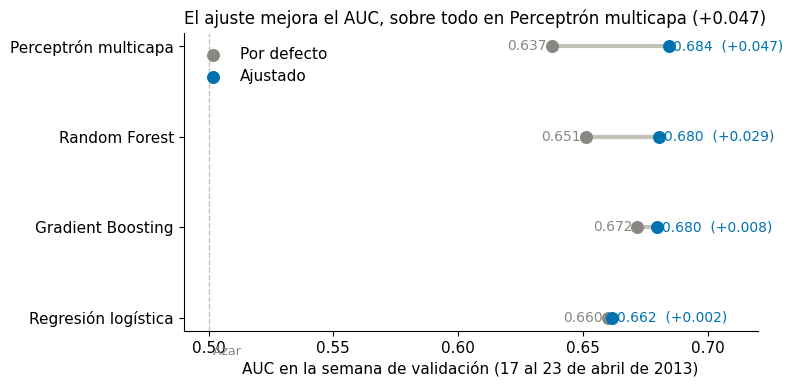

In [15]:
orden = mejora.sort_values('auc_ajustado')
fig, ax = plt.subplots(figsize=(8, 4))
posiciones = np.arange(len(orden))
ax.hlines(posiciones, orden['auc_por_defecto'], orden['auc_ajustado'], color=GRIS_CLARO, linewidth=3, zorder=1)
ax.scatter(orden['auc_por_defecto'], posiciones, color=GRIS, s=70, zorder=2, label='Por defecto')
ax.scatter(orden['auc_ajustado'], posiciones, color=AZUL, s=70, zorder=3, label='Ajustado')
for y, (_, fila) in zip(posiciones, orden.iterrows()):
    ax.text(fila['auc_ajustado'] + 0.002, y, f"{fila['auc_ajustado']:.3f}  ({fila['mejora_auc']:+.3f})", va='center', color=AZUL, fontsize=10)
    ax.text(fila['auc_por_defecto'] - 0.002, y, f"{fila['auc_por_defecto']:.3f}", va='center', ha='right', color=GRIS, fontsize=10)
ax.axvline(0.5, color=GRIS_CLARO, linestyle='--', linewidth=1)
ax.text(0.5, -0.45, ' Azar', color=GRIS, fontsize=9, va='bottom')
ax.set_yticks(posiciones)
ax.set_yticklabels([NOMBRES[a] for a in orden['algoritmo']])
ax.set_xlim(0.49, 0.72)
ax.set_xlabel('AUC en la semana de validación (17 al 23 de abril de 2013)')
mayor = orden.loc[orden['mejora_auc'].idxmax()]
ax.set_title(f"El ajuste mejora el AUC, sobre todo en {NOMBRES[mayor['algoritmo']]} ({mayor['mejora_auc']:+.3f})", loc='left', fontsize=12)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '07_mejora_auc_por_ajuste.png', dpi=150, bbox_inches='tight')
plt.show()

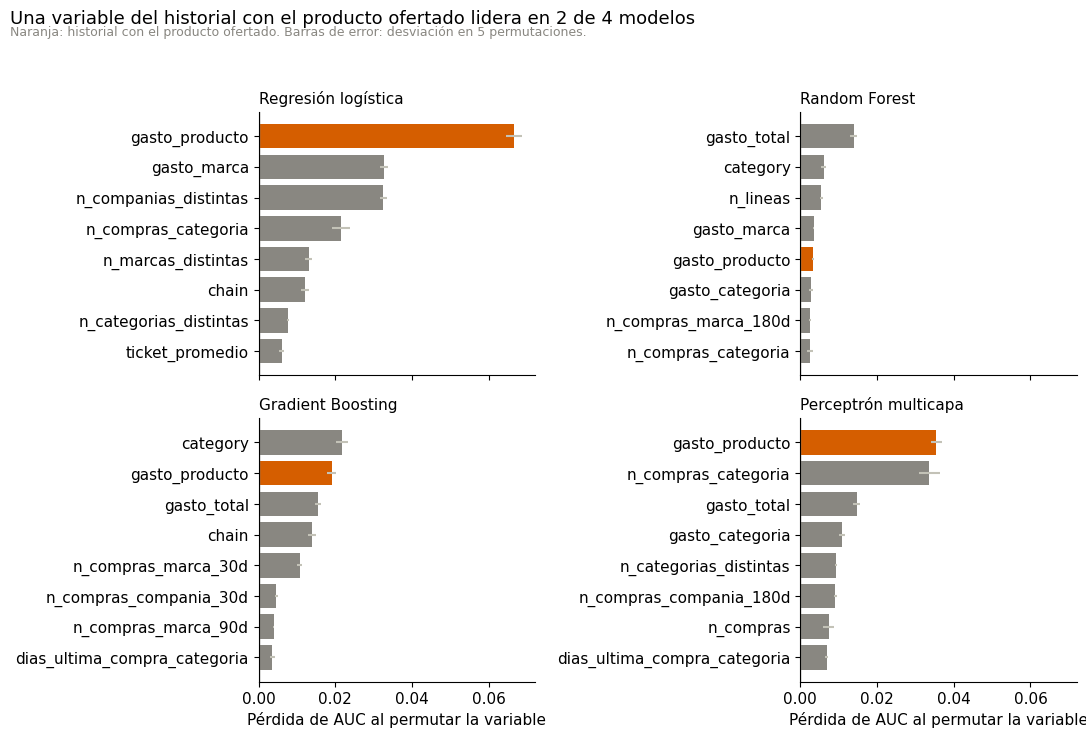

In [16]:
def es_historial_producto(variable):
    return 'producto' in variable

fig, ejes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, algoritmo in zip(ejes.ravel(), ALGORITMOS):
    top = importancia[importancia['algoritmo'] == algoritmo].head(8).iloc[::-1]
    colores = [NARANJA if es_historial_producto(v) else GRIS for v in top['variable']]
    ax.barh(top['variable'], top['perdida_auc'], xerr=top['desviacion'], color=colores, error_kw={'ecolor': GRIS_CLARO})
    ax.set_title(NOMBRES[algoritmo], loc='left', fontsize=11)
    ax.axvline(0, color=GRIS, linewidth=1)
for ax in ejes[1]:
    ax.set_xlabel('Pérdida de AUC al permutar la variable')
lider = importancia.groupby('algoritmo').head(1)
con_producto = int(lider['variable'].map(es_historial_producto).sum())
fig.suptitle(
    f'Una variable del historial con el producto ofertado lidera en {con_producto} de 4 modelos',
    x=0.01, ha='left', fontsize=13,
)
fig.text(0.01, 0.945, 'Naranja: historial con el producto ofertado. Barras de error: desviación en 5 permutaciones.', color=GRIS, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGURES_DIR / '07_importancia_permutacion.png', dpi=150, bbox_inches='tight')
plt.show()

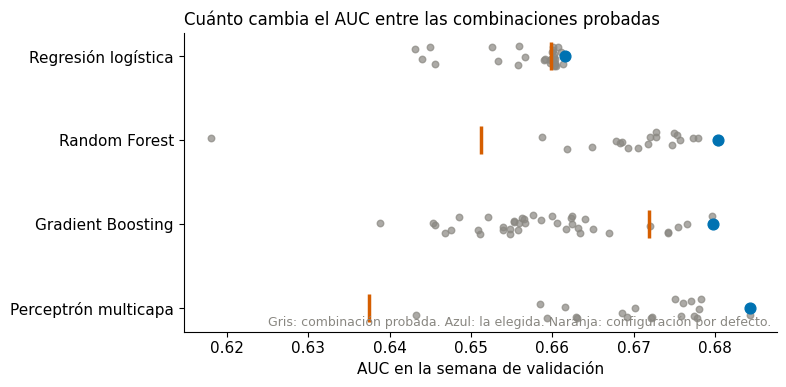

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
generador = np.random.default_rng(0)
for i, algoritmo in enumerate(ALGORITMOS):
    puntos = busqueda.loc[busqueda['algoritmo'] == algoritmo, 'auc_validacion']
    ax.scatter(puntos, i + generador.uniform(-0.12, 0.12, len(puntos)), color=GRIS, s=22, alpha=0.7)
    por_defecto = mejora.set_index('algoritmo').loc[algoritmo, 'auc_por_defecto']
    ax.scatter([por_defecto], [i], color=NARANJA, marker='|', s=400, linewidths=2.5)
    ax.scatter([puntos.max()], [i], color=AZUL, s=60, zorder=3)
ax.set_yticks(range(len(ALGORITMOS)))
ax.set_yticklabels([NOMBRES[a] for a in ALGORITMOS])
ax.invert_yaxis()
ax.set_xlabel('AUC en la semana de validación')
ax.set_title('Cuánto cambia el AUC entre las combinaciones probadas', loc='left', fontsize=12)
ax.text(0.99, 0.02, 'Gris: combinación probada. Azul: la elegida. Naranja: configuración por defecto.', transform=ax.transAxes, ha='right', color=GRIS, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '07_busqueda_hiperparametros.png', dpi=150, bbox_inches='tight')
plt.show()